# Занятие 8. Развертываем проект: самостоятельная работа

После выполнения инструкции ваш агент будет отвечать в личном чате Telegram, сохранять разговоры в Postgres и писать трейсы в Langfuse.
Сначала запустите готовый пример и проверьте инфраструктуру. Затем подключите своего агента: так будет проще найти причину возможной ошибки.
На выполнение понадобится Docker, доступ к модели и токен бота от @BotFather. Langfuse можно подключить после первого успешного ответа API.

Все файлы находятся в [deploy/session-08](../../deploy/session-08/README.md) в том же репозитории. Приватный репозиторий курса для этой работы не требуется.
Команды в блоках `bash` выполняйте в терминале из папки `deploy/session-08`. В Windows подойдет терминал WSL2 с подключенным Docker Desktop.
Ячейки Python только показывают файлы шаблона. Run All не запускает контейнеры и не отправляет сообщения. Основные действия выполняются командами ниже.


## 1. Что будет запущено

Бот получает сообщение из Telegram и отправляет HTTP-запрос в API. Только API создает агента и обращается к базе данных.
В Postgres сохраняются история разговоров, ожидающие подтверждения и записи долгосрочной памяти. Langfuse получает события выполнения отдельно от ответов пользователю.
Бот собирает ответ из потока и отправляет готовый текст. Постепенное появление текста в Telegram здесь не реализовано.

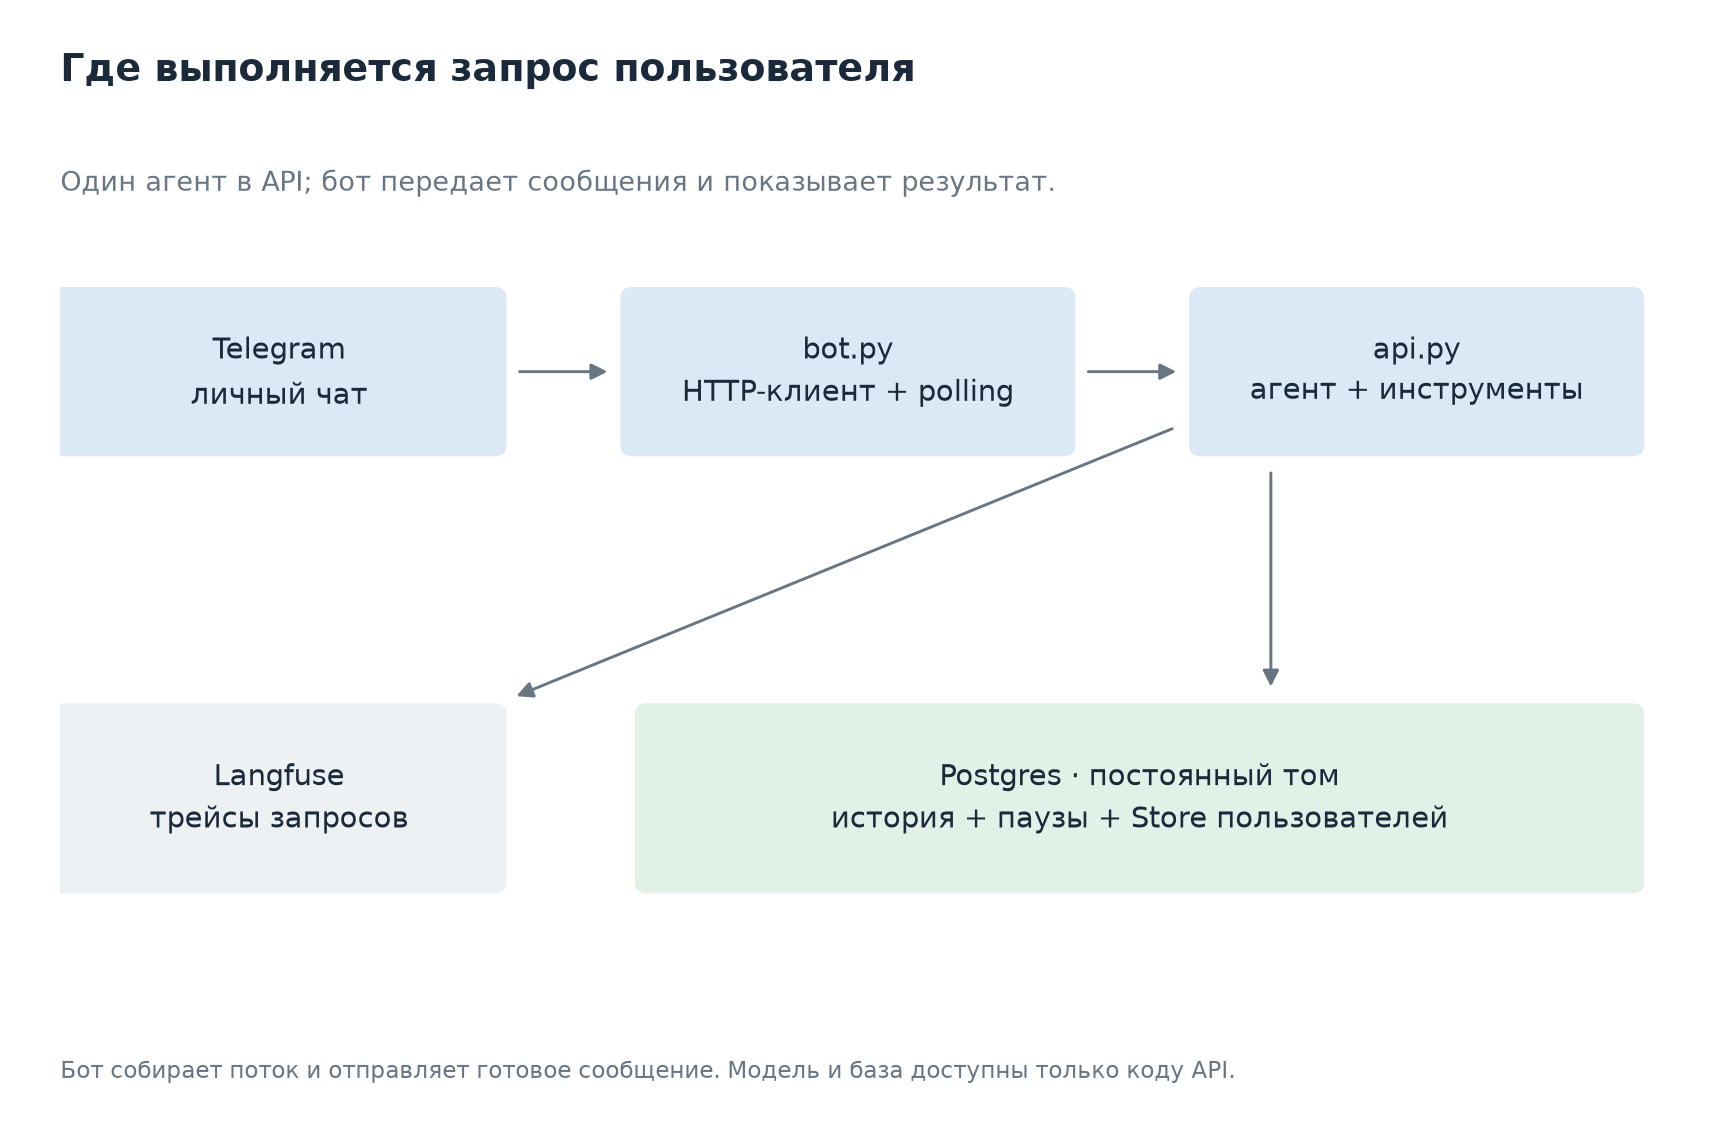


## 2. Проверьте инструменты

Установите [Docker Desktop](https://docs.docker.com/get-started/get-docker/) или Docker Engine с Compose, а также [uv](https://docs.astral.sh/uv/getting-started/installation/).
Запустите Docker. Следующие команды должны показать версии и список контейнеров без ошибки подключения к daemon:

```bash
docker version
docker compose version
uv --version
```

Перейдите в `deploy/session-08` внутри скачанных материалов. Проверьте, что рядом лежат `compose.yaml`, `Dockerfile`, `uv.lock` и `.env.example`.
При переносе в свой репозиторий скопируйте всю папку, включая скрытые файлы. База и модель не нужны для проверки установленных зависимостей:

```bash
uv sync --frozen
uv run pytest -q
```

`uv` установит Python 3.12 при необходимости. Lock-файл фиксирует зависимости; не удаляйте его при первой установке. Ожидаемый результат тестов: `12 passed`.


In [ ]:
# Найти файлы инструкции при запуске из Jupyter или из репозитория.

from pathlib import Path

candidates = [Path("../../deploy/session-08"), Path("deploy/session-08"), Path("materials/deploy/session-08")]
PROJECT = next(path.resolve() for path in candidates if (path / "compose.yaml").is_file())
required = ["agent.py", "api.py", "bot.py", "client.py", "check.py", "compose.yaml", "Dockerfile", "uv.lock"]
missing = [name for name in required if not (PROJECT / name).is_file()]
assert not missing, missing
print("Template files:", ", ".join(required))  # ключи и .env не читаются


### Как распределены файлы

| Файл | Что в нем менять |
|---|---|
| `agent.py` | Сборка вашего агента, инструменты и промпт |
| `api.py` | HTTP-вход, поток ответов, сохранение состояния и продолжение после подтверждения |
| `client.py` | Запросы из терминала и общий разбор потока для бота |
| `bot.py` | Получение сообщений Telegram, показ ответа и кнопок подтверждения |
| `compose.yaml`, `Dockerfile` | Запуск API, базы и бота |
| `check.py` | Настройка и проверка доступности без печати секретов |

Начните с готовых файлов. Полный код можно прочитать по ссылкам в папке шаблона; ниже также есть ячейки, которые его печатают.


## 3. Создайте настройки

Из папки шаблона выполните:

```bash
uv run python check.py init
```

Команда создаст `.env` и сгенерирует разные случайные секреты для API и базы. Существующий `.env` она не перезаписывает.
Откройте файл редактором. Перенесите рабочие `LLM_PROVIDER`, `LLM_API_KEY`, `LLM_BASE_URL`, `MODEL_CHEAP` и при необходимости `LLM_REASONING_EFFORT` из предыдущих занятий.
Для Gemini используется `LLM_PROVIDER=google_genai`; адрес OpenAI-совместимого API в этой ветке не используется.
Пока оставьте `TELEGRAM_BOT_TOKEN` и ключи Langfuse пустыми. Затем проверьте настройки:

```bash
uv run python check.py env
```

Ожидается `Required .env settings: OK`. Если перечислены имена полей, заполните их и повторите проверку.
Пароль Postgres оставьте сгенерированным: он безопасен для включения в URL. `.env` уже исключен из Git и Docker-контекста.


### Адреса на компьютере и внутри Docker

`localhost` означает тот процесс или контейнер, из которого выполнено обращение. Поэтому адреса клиента и бота различаются.

| Кто обращается | Куда | Адрес по умолчанию |
|---|---|---|
| Вы из терминала | API | `http://localhost:8108` |
| Бот внутри Docker | API | `http://api:8000` |
| API внутри Docker | Postgres | `db:5432` |
| API внутри Docker | Langfuse на компьютере | `http://host.docker.internal:3000` |

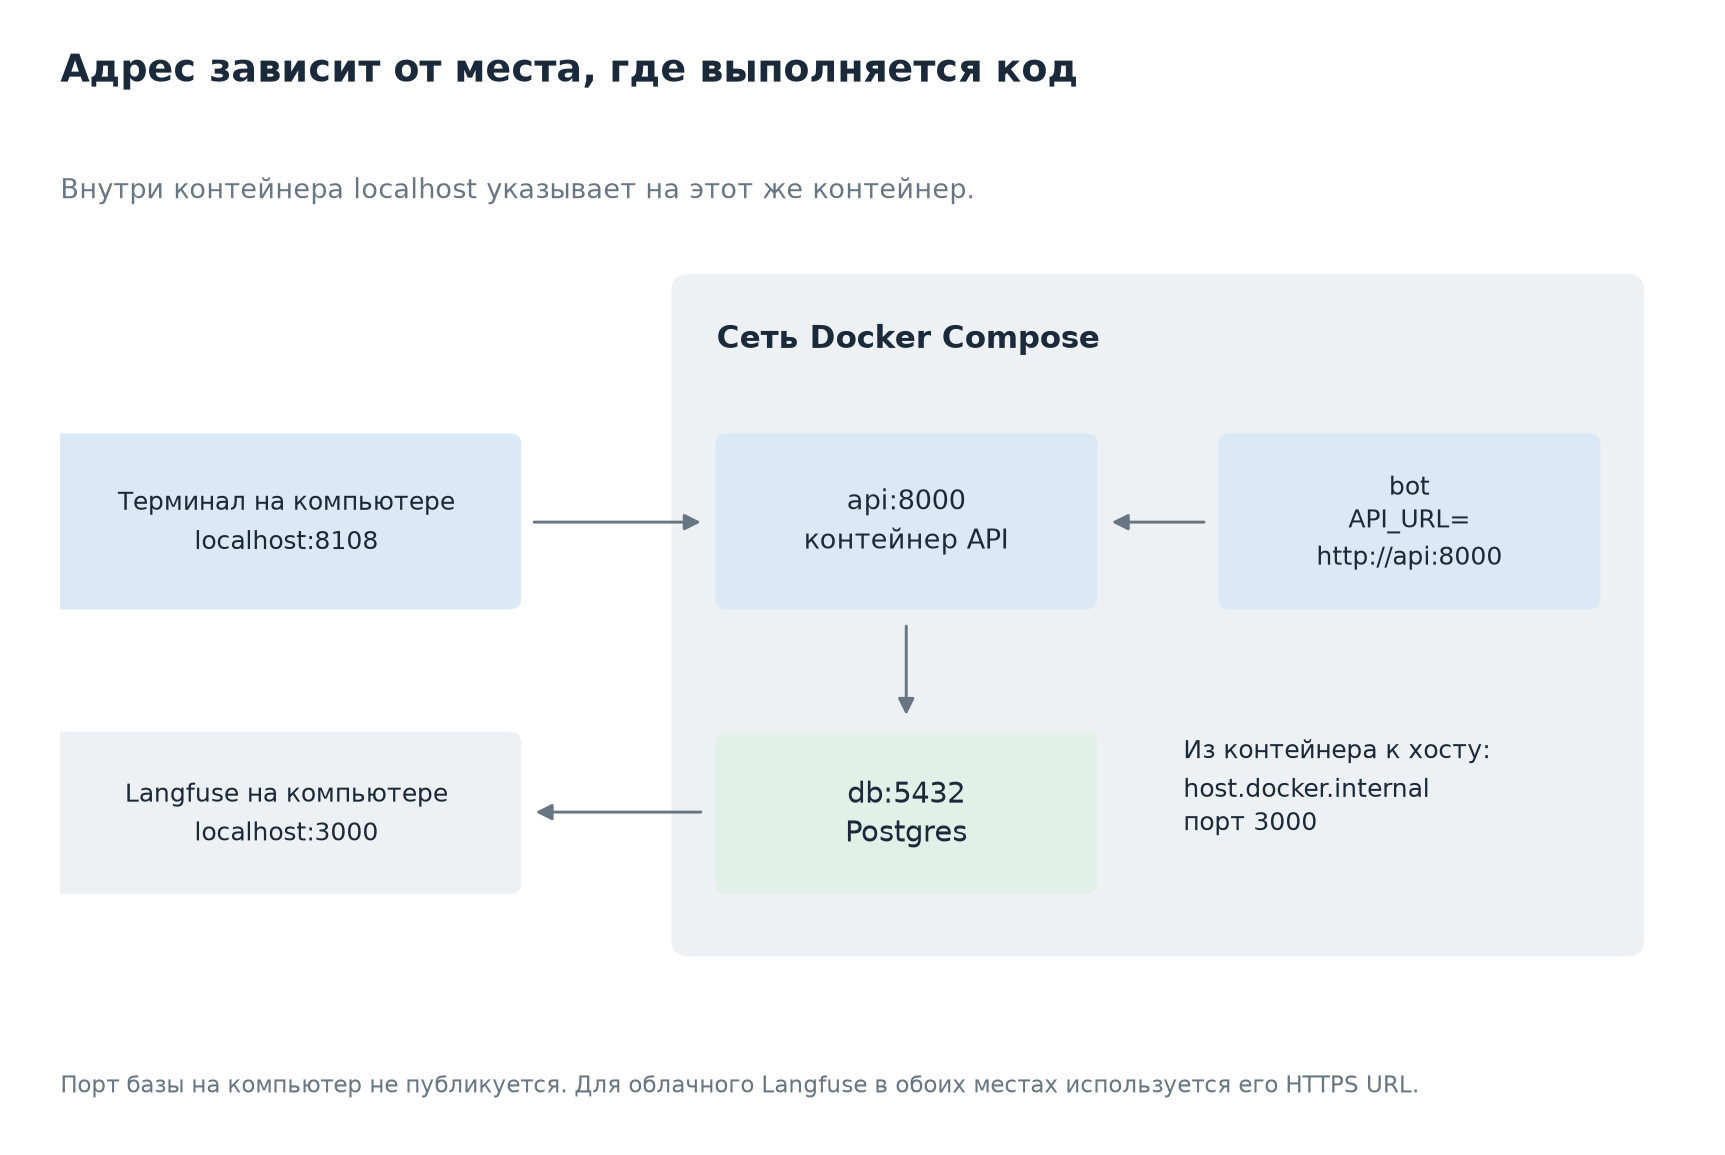

В `compose.yaml` адрес базы задается автоматически. Если модель работает на вашем компьютере, ее адрес тоже должен быть доступен из контейнера.
Для облачного API используйте выданный провайдером HTTPS URL. Если порт 8108 занят, измените одновременно `API_PORT` и порт в `API_URL` файла `.env`.


## 4. Запустите API и Postgres

```bash
docker compose up -d --build --wait api
uv run python check.py health
```

Первая сборка скачивает зависимости и может занять несколько минут. `--wait` ждет успешной проверки готовности API.
Ожидаемый результат: `{"status": "ok", "persistence": "postgres"}`. Если указан `memory`, вы подключились к другому процессу API.
База не публикует порт на компьютер. API доступен только на локальном адресе; бот подключится к нему через сеть Compose.

```bash
docker compose ps
docker compose logs --tail=80 api
```

В списке должны быть здоровые `api` и `db`. Ошибка сборки находится в выводе первой команды; ошибка запуска приложения находится в логах `api`.


In [ ]:
# Показать запускаемые сервисы и постоянный том базы.

print((PROJECT / "compose.yaml").read_text())  # .env сюда не подставляется


### Почему база успевает подготовиться

`depends_on` с `service_healthy` ждет, пока Postgres начнет принимать соединения. Затем `lifespan` API открывает соединения с базой и выполняет `setup()`.
`setup()` создает необходимые таблицы и применяет миграции. Соединения остаются открытыми до завершения приложения.
Именованный том `project-data` хранит файлы Postgres отдельно от контейнера API. Бот запускается отдельным сервисом только после включения профиля `telegram`.
Файл Dockerfile собирает один образ для API и бота. В нем установлен один worker: защита от параллельных запросов одного разговора рассчитана на один процесс API.


## 5. Получите первый ответ через API

```bash
uv run python client.py "Где посылка RR-1001?" --thread demo --user student
uv run python client.py "Какую посылку я спрашивал?" --thread demo --user student
uv run python check.py state --thread demo --user student
```

Первый ответ должен назвать статус и перевозчика. Второй должен вспомнить RR-1001. Точная формулировка зависит от модели.
Команда состояния показывает число сохраненных сообщений и список ожидающих подтверждений. Число сообщений может различаться из-за вызовов инструментов.
`thread` выбирает разговор, `user` выбирает пользователя. При продолжении сохраняйте оба значения. Другой `thread` начинает новый разговор того же пользователя.
`client.py` сам добавляет API-токен из `.env`. Этот общий токен разрешает обращаться к учебному серверу; полноценные учетные записи пользователей здесь не реализованы.


In [ ]:
# Показать клиент, который одинаково разбирает ответы для терминала и Telegram.

print((PROJECT / "client.py").read_text())


### Как передается ответ

API возвращает SSE: один HTTP-ответ остается открытым, а внутри приходят события. В поле `data:` всегда находится JSON.

| Тип события | Что делает клиент |
|---|---|
| `text` | Добавляет фрагмент к ответу; переносы строк находятся внутри JSON-строки |
| `interrupt` | Показывает имя действия, аргументы и доступные решения |
| `done` | Завершает чтение; `waiting=true` означает ожидание решения |
| `error` | Показывает ошибку; частичный текст не выдается за успешный ответ |

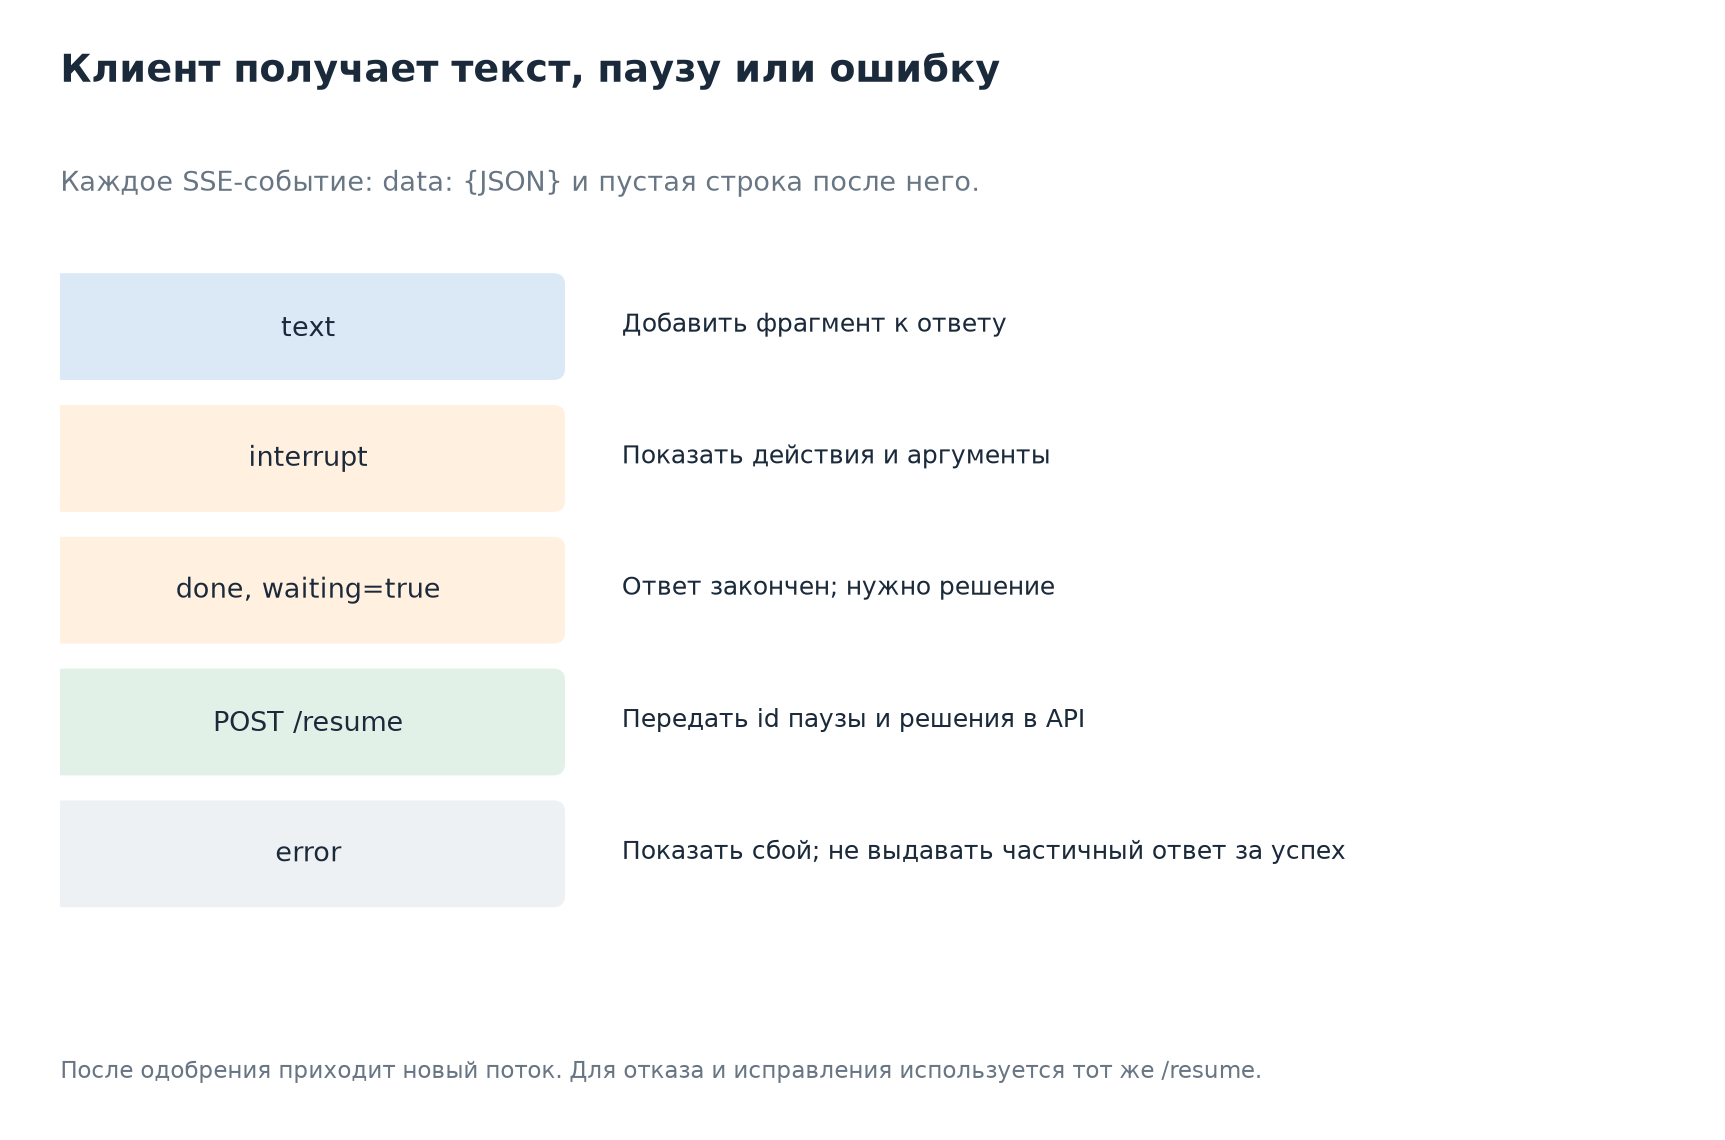

Текстовые события могут включать пояснение модели перед инструментом. Ошибка после начала HTTP-ответа передается событием: уже отправленный статус 200 заменить нельзя.
Бот собирает фрагменты и отправляет готовое сообщение. Тесты проверяют сохранность переводов строк, обрыв потока и ошибку вместо завершения.


In [ ]:
# Показать реализацию HTTP-входа и обработки сохраненной паузы.

print((PROJECT / "api.py").read_text())


## 6. Проверьте память после перезапуска

Сначала выполните два запроса из шага 5. Затем:

```bash
docker compose restart api
docker compose up -d --wait api
uv run python check.py health
uv run python client.py "Назови номер посылки из нашего разговора" --thread demo --user student
```

Ответ должен содержать RR-1001, хотя процесс API уже другой. Номер не передается в новом вопросе: он берется из сохраненной истории.

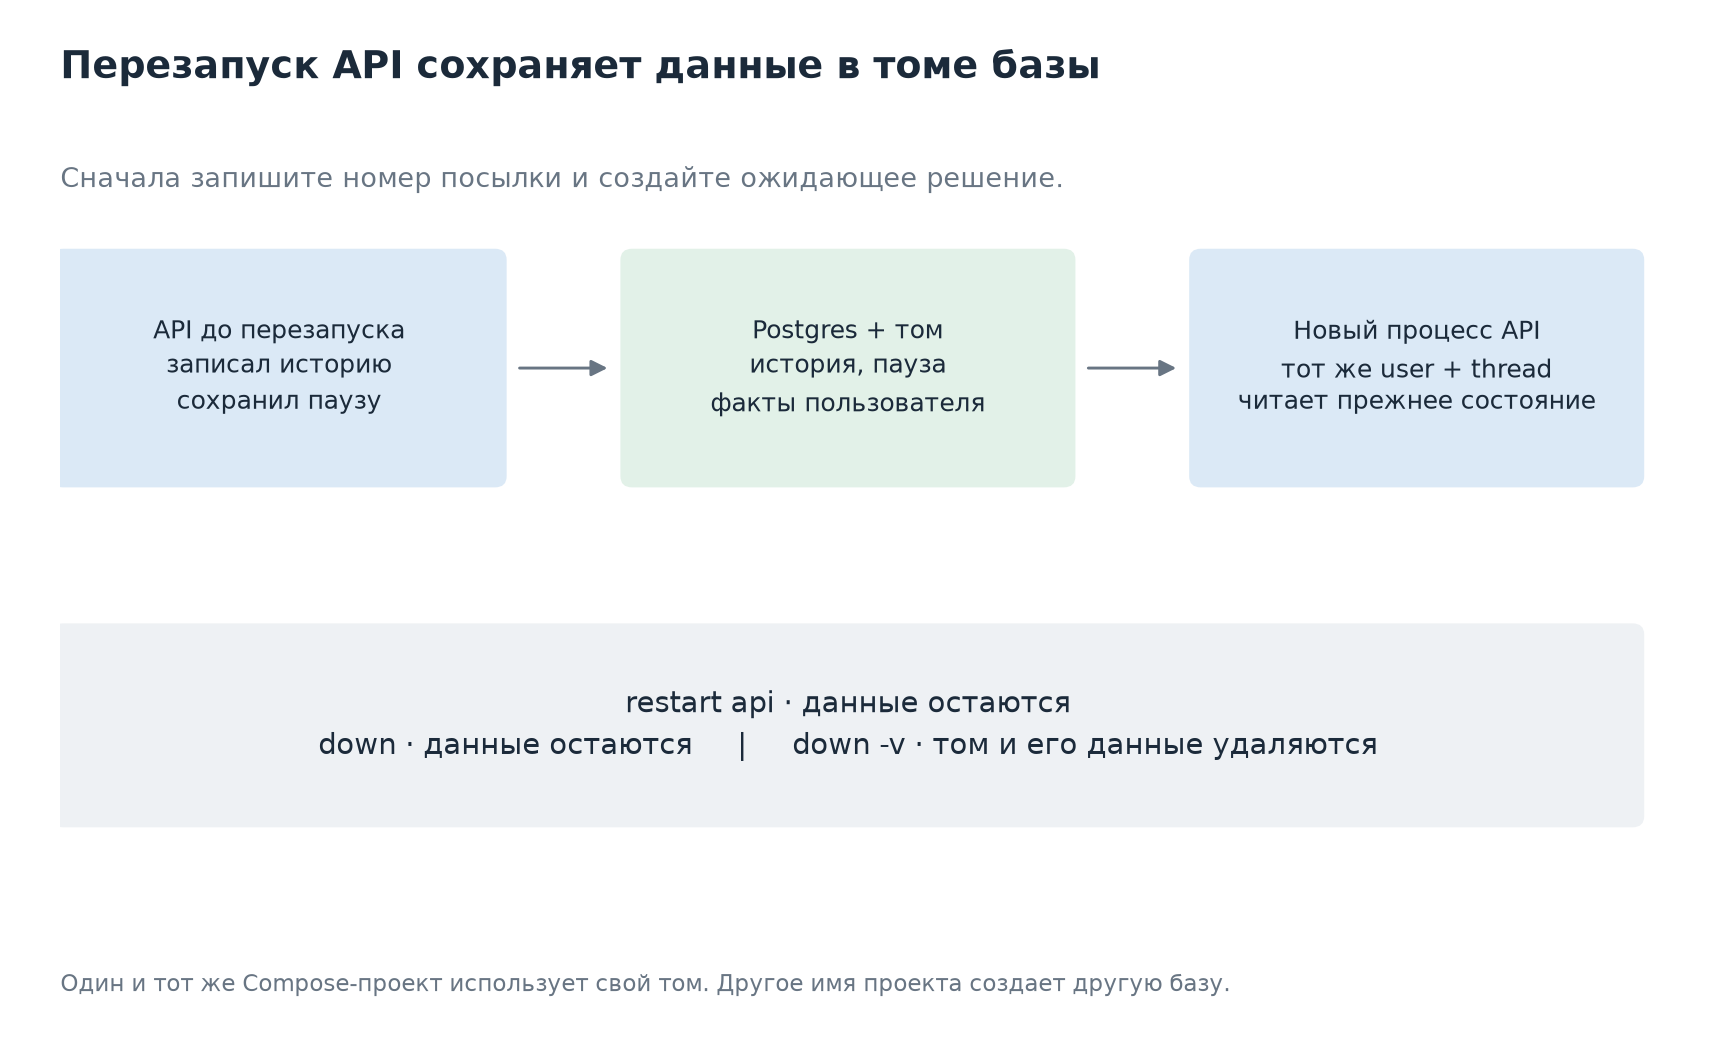

`docker compose restart api` сохраняет базу и ее том. Команда `docker compose down` тоже сохраняет том; `down -v` удаляет его вместе с учебными данными.
Изменение `.env` требует `docker compose up -d --force-recreate api`; изменение кода требует `docker compose up -d --build api`.


### Долгосрочная память тоже хранится в Postgres

В шаблоне подключены готовые инструменты LangMem. Проверьте отдельную запись для пользователя:

```bash
uv run python client.py "Запомни на будущее: я предпочитаю доставку вечером" --thread preferences --user student
```

Дождитесь подтверждения записи. Перезапустите API, затем начните другой разговор того же пользователя:

```bash
docker compose restart api
docker compose up -d --wait api
uv run python client.py "Какое время доставки я предпочитаю? Проверь сохраненную память" --thread another --user student
```

Ожидается предпочтение вечерней доставки. Для `--user another-student` эта запись недоступна. В шаблоне поиск памяти перечисляет записи без векторного индекса.
Чекпоинтер хранит историю по разговору, Store хранит факты по пользователю. Подключение Postgres не переносит автоматически старые данные из SQLite или Mem0.


## 7. Проверьте подтверждение действия

Готовый пример предлагает записать заявку на доставку. Реальной отправки заявки нет; инструмент возвращает учебное подтверждение.

```bash
uv run python client.py "Создай заявку на доставку завтра в 18:00" --thread approval --user student
uv run python check.py state --thread approval --user student
```

В выводе должна быть пауза: имя `request_delivery`, аргумент `note`, доступные решения и `id`. Пока решение не получено, действие не выполнено.
Перезапустите API и снова прочитайте состояние: пауза должна сохраниться. Скопируйте ее id вместо `PAUSE_ID`:

```bash
uv run python client.py "" --thread approval --user student --decision approve --interrupt PAUSE_ID
```

Ожидается ответ о выполненной учебной заявке. Повторное применение того же id отклоняется: старая кнопка не должна повторять действие.
Для отказа используйте `--decision reject`. Новое сообщение в разговор с ожидающим решением получает 409; сначала обработайте паузу.


### Исправление аргументов и собственные прерывания

Для одной ожидающей заявки можно передать полные исправленные аргументы:

```bash
uv run python client.py "" --thread approval --user student --decision edit --interrupt PAUSE_ID --args '{"note":"Доставка в пятницу после 19:00"}'
```

Команда предназначена для новой, еще не обработанной паузы. В PowerShell удобнее выполнить ее через WSL2, чтобы сохранить кавычки JSON.
API поддерживает формат пауз `HumanInTheLoopMiddleware`. У каждого действия проверяется допустимость решения; порядок решений совпадает с порядком действий.
Если ваш проект вызывает собственный `interrupt()` с другим содержимым, добавьте клиентское представление и формат продолжения для него.
Внешние операции после подтверждения должны учитывать повтор запроса при сетевом сбое; этот шаблон не обещает ровно одну отправку в стороннем сервисе.


## 8. Подключите Telegram

Откройте [@BotFather](https://t.me/BotFather) в Telegram, выполните `/newbot` и задайте имя и свободный username. Полученный токен сохраните в `.env` как `TELEGRAM_BOT_TOKEN`.
Один токен должен обслуживаться одним запущенным процессом polling. Остановите прежнюю копию этого бота, если она уже работает на другом компьютере.

```bash
docker compose --profile telegram up -d --build --wait
```

Откройте своего бота по username и напишите «Где посылка RR-1001?». Затем спросите номер посылки без повторного указания номера.
Бот работает в личных чатах. Для групп возвращается просьба написать лично, чтобы несколько людей не делили историю и память.
Пришлите запрос на заявку из шага 7. Бот покажет аргументы и кнопки «Одобрить все» и «Отклонить все».
Перезапустите API до нажатия кнопки: решение должно примениться к сохраненной паузе. Редактирование аргументов доступно через клиент из терминала.


In [ ]:
# Показать Telegram-клиент: HTTP-запросы, вывод ответа и решения человека.

print((PROJECT / "bot.py").read_text())


### Если бот молчит

```bash
docker compose --profile telegram ps
docker compose logs --tail=80 bot api
```

Сначала проверьте ответ API через `client.py`. Если API отвечает, ищите проблему в токене, доступе к Telegram или втором процессе polling.
`Unauthorized` от Telegram обычно означает неправильный токен; `Conflict` при `getUpdates` означает другой polling-процесс или установленный webhook.
Если раньше бот работал через webhook, удалите его через Bot API `deleteWebhook` с вашим токеном, затем перезапустите polling.
Фотография или стикер получают просьбу прислать текст. Бот преобразует Markdown модели в обычный текст и разбивает длинные ответы на сообщения.
Карточка подтверждения показывает действие и все его аргументы, без служебного описания middleware.
Long polling делает исходящие запросы к Telegram. Публичный адрес и настройка webhook для этого запуска не требуются.


## 9. Подключите Langfuse из предыдущих занятий

Перенесите ключи проекта в `LANGFUSE_PUBLIC_KEY` и `LANGFUSE_SECRET_KEY`. `LANGFUSE_BASE_URL` используется при проверке с компьютера.
`LANGFUSE_DOCKER_URL` должен быть доступен из контейнера: для локального сервера это `http://host.docker.internal:3000`, для облака его HTTPS URL.
Повторно разворачивать весь Langfuse в этом Compose не требуется.

```bash
uv run python check.py tracing
docker compose up -d --force-recreate --wait api
docker compose exec api python check.py tracing
```

Обе проверки должны напечатать `Langfuse connection: OK`. После этого напишите боту и найдите новый трейс `project/chat` с тегами `session-08`, `api`.
Сессия имеет вид `USER_ID:CHAT_ID`; user_id совпадает с идентификатором пользователя Telegram. Ответ и решение подтверждения относятся к одному разговору.
Трейс дополняет обычные логи. Сумма USD в Langfuse требует настроенных цен модели, как разбиралось на занятии 7.


## 10. Подключите свой проект

Измените `build_agent(checkpointer, store)` в `agent.py`: импортируйте свои инструменты, промпт и middleware, передайте полученные объекты в `create_agent`.
Для ручного LangGraph передайте их в `graph.compile(checkpointer=checkpointer, store=store)`. Фабрика должна вернуть граф с `messages`, `astream` и `aget_state`.
Не создавайте внутри фабрики новый InMemorySaver вместо переданного чекпоинтера. Иначе сервис потеряет историю после перезапуска.
Существующие middleware обрезки или суммаризации можно сохранить. HumanInTheLoopMiddleware не отключайте: клиент уже умеет показывать его паузы.
Если используете Store, возьмите переданный постоянный объект. Для внешних сервисов памяти сохраните их подключение и пользовательские пространства имен.
Имена пользователя для LangMem берутся из `configurable.user_id`; идентификатор разговора передается отдельно. Проверьте изоляцию двух пользователей своего проекта.


In [ ]:
# Показать единственный файл, который требуется заменить для своего проекта.

print((PROJECT / "agent.py").read_text())


### После замены агента

Добавьте зависимости проекта в `pyproject.toml` через `uv add ИМЯ_ПАКЕТА`. Сохраните обновленный `uv.lock` в Git.

```bash
uv run pytest -q
docker compose up -d --build --wait api
docker compose --profile telegram up -d --build bot
```

Тесты шаблона проверяют учебные инструменты. После замены `agent.py` обновите их сценарии под свой проект, сохранив проверки HTTP и протокола.
Начните новый разговор для новой схемы агента: чекпоинты старого графа могут быть несовместимы. Для удаления только учебных данных используйте отдельный Compose-проект.
Повторите проверки ответа, продолжения разговора, сохранения после перезапуска, памяти и подтверждения действия.


## Если проверка остановилась

| Симптом | Что проверить |
|---|---|
| `port is already allocated` | Порт в `API_PORT` занят; измените его вместе с `API_URL` |
| API не стал healthy | `docker compose logs --tail=80 api db`; ключи и доступ к модели проверяются первым запросом |
| `401` от API | Совпадает ли `API_TOKEN` клиента с настройкой пересозданного контейнера |
| `401` или `429` от модели в логах | Ключ, баланс, лимиты и имя модели у провайдера |
| `409` | Разговор еще выполняется или ждет решения; прочитайте `/state` через check.py |
| `422` | Не переданы text/user_id, неверное решение или неполные аргументы edit |
| История исчезла | Health должен показывать postgres; проверьте thread/user и прежнее имя Compose-проекта |
| Langfuse не получает трейс | Проверка tracing из контейнера, адрес и ключи проекта |
| После смены пароля Postgres не пускает | Пароль в уже существующем томе не меняется от правки .env; верните прежний пароль |

Ошибка модели после начала потока записывается в логи и отправляется клиенту событием `error`. Клиент не объявляет частичный текст успешным ответом.
Сохраните точную команду и текст ошибки без ключей. Это полезнее для разбора, чем повторный Run All ноутбука.


## Что сохранить в своем репозитории

В `runs/session-08.md` запишите username бота, команды запуска, ответы до и после перезапуска API и ссылку на трейс.
Если проект использует память или подтверждение, добавьте проверку этой функции после перезапуска. Укажите, какой вопрос и какое решение использовались.
Коммитьте код, lock-файл и `.env.example`; `.env` и токены остаются локально. В переписках и выгрузках удалите персональные данные, которые не нужны для проверки.
Другому человеку должно хватить вашего README и собственной настройки ключей, чтобы повторить запуск.

Для остановки без удаления данных:

```bash
docker compose --profile telegram down
```


## Перенос на сервер

Скопируйте репозиторий на Linux-сервер с Docker и uv, создайте там отдельный `.env` и повторите команды запуска.
Для Telegram с long polling публичный HTTP-вход не требуется: API может остаться на 127.0.0.1, бот обращается к нему внутри Compose.
Остановите локальный экземпляр бота перед запуском серверного. Локальный Langfuse с вашего ноутбука на сервере недоступен; задайте достижимый URL.
Для публичного веб-клиента сначала добавьте HTTPS и авторизацию конечных пользователей: общий API_TOKEN дает доступ ко всем учебным разговорам.
Храните резервную копию базы перед обновлением зависимостей или схемы своего агента. Несколько workers и горизонтальное масштабирование требуют общей координации запросов.


## Справка

- [Быстрый запуск Docker Compose](https://docs.docker.com/compose/gettingstarted/) и [порядок готовности сервисов](https://docs.docker.com/compose/how-tos/startup-order/).
- [Установка uv](https://docs.astral.sh/uv/getting-started/installation/).
- [История и постоянная память LangGraph](https://docs.langchain.com/oss/python/langgraph/persistence).
- [Long polling в aiogram](https://docs.aiogram.dev/en/latest/dispatcher/long_polling.html).
- [LangChain в Langfuse](https://langfuse.com/integrations/frameworks/langchain).

Работа завершена, когда свой агент отвечает через Telegram, продолжает разговор после перезапуска и оставляет находимый трейс.
